# 01 · Quantics tensor trains (Sec. II A, Fig. 2)

A wavefunction $\psi_n$ on $N=2^R$ Fock states becomes a tensor with $R$ binary indices,
$n=\sum_{i=1}^R 2^{R-i}\sigma_i$ (MSB first, Eq. 4), which is then factorised as a tensor train (Eq. 6).
The bond dimension $\chi_q$ measures correlations **between scales** of $n$, not entanglement between particles; that is why it stays small for smooth amplitudes.

What you will see:
1. the quantics index map;
2. TT-SVD of a coherent state with $|\alpha|^2 = 2^R/3$ — rank roughly independent of $R$, so memory grows like $R$ instead of $2^R$;
3. the same state in a position grid, the alternative representation of Eq. 7.

**Tolerances.** Everywhere in `qttlind` (the solver, the oracle and these helpers) a compression tolerance `tol` is the *discarded relative weight* per bond, $\sum_{j\ge k}s_j^2/\sum_j s_j^2$, i.e. the square of the relative Frobenius error. So `tol=1e-20` means a relative error of $10^{-10}$. See `CONVENTIONS.md`.

In [1]:
import os, sys
from tutorial_utils import *
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print(backend_banner())
PAPER_SIZE = HAVE_QTTLIND and os.environ.get("QTTLIND_PAPER_SIZE") == "1"   # published sizes (hours); default: quick mode

qttlind 2.0.0, QTT solver: quick mode (set QTTLIND_PAPER_SIZE=1 for the published sizes).


In [2]:
R = 4
for n in [0, 1, 5, 10, 15]:
    s = bits_of(n, R)
    assert index_of(s) == n
    print(f"n = {n:2d}  ->  sigma = {s}")

n =  0  ->  sigma = [0, 0, 0, 0]
n =  1  ->  sigma = [0, 0, 0, 1]
n =  5  ->  sigma = [0, 1, 0, 1]
n = 10  ->  sigma = [1, 0, 1, 0]
n = 15  ->  sigma = [1, 1, 1, 1]


## Fig. 2 — from a function on $2^R$ points to an $R$-index tensor

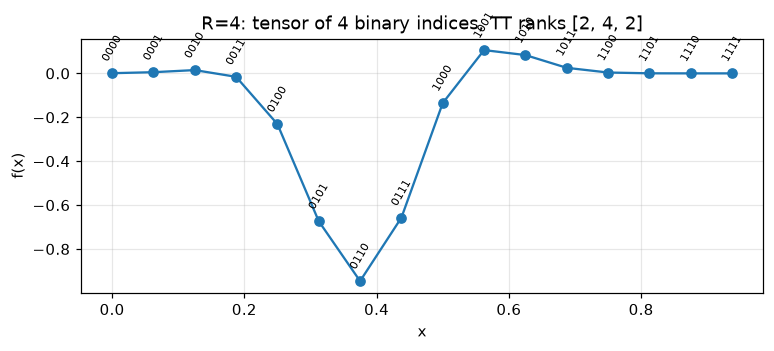

reconstruction error: 2.983724378680108e-16


In [3]:
R = 4
x = np.linspace(0, 1, 2**R, endpoint=False)
f = np.exp(-((x - 0.4) / 0.15)**2) * np.cos(9 * x)
cores = tt_svd(f, R, tol=1e-24)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(x, f, "o-")
for j, xj in enumerate(x):
    ax.annotate("".join(map(str, bits_of(j, R))), (xj, f[j]), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=7, rotation=60)
ax.set(xlabel="x", ylabel="f(x)", title=f"R={R}: tensor of {R} binary indices, TT ranks {tt_ranks(cores)}")
plt.show()
print("reconstruction error:", np.abs(tt_to_dense(cores) - f).max())

## Coherent states: rank vs number of bits

We sweep $R$ with $|\alpha|^2 = 2^R/3$ (the scaling used in Figs. 4 and 10) and record the maximal QTT rank at a discarded weight $10^{-20}$ per bond (relative norm error $10^{-10}$; see the note on tolerances above), together with the memory of the tensor train versus the $2^R$ dense vector.

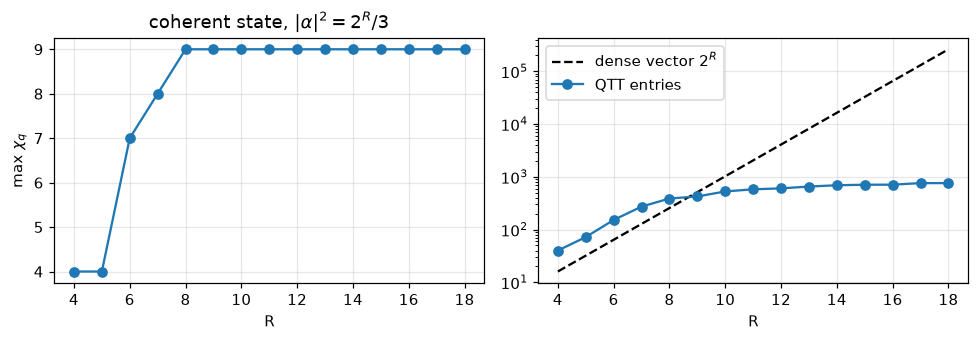

In [4]:
Rs = list(range(4, 19 if not PAPER_SIZE else 23))
rows = []
for R in Rs:
    N = 2**R
    v = dr.coherent(N, np.sqrt(N / 3))
    if "qtt" in ql.FEATURES:           # qttlind.TensorTrain
        ranks = list(ql.TensorTrain.from_dense(v, [2] * R, tol=1e-20).ranks)
    else:
        ranks = tt_ranks(tt_svd(v, R, tol=1e-20))
    mem = sum(r1 * 2 * r2 for r1, r2 in zip([1] + ranks, ranks + [1]))
    rows.append((R, max(ranks), mem, N))
rows = np.array(rows)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(rows[:, 0], rows[:, 1], "o-"); ax[0].set(xlabel="R", ylabel=r"max $\chi_q$", title=r"coherent state, $|\alpha|^2=2^R/3$")
ax[1].semilogy(rows[:, 0], rows[:, 3], "k--", label="dense vector $2^R$")
ax[1].semilogy(rows[:, 0], rows[:, 2], "o-", label="QTT entries"); ax[1].set(xlabel="R"); ax[1].legend()
plt.tight_layout(); plt.show()

## Same state in position space (Eq. 7)

$\psi(x)=\sum_n \psi_n \phi_n(x)$ sampled on $2^{R_x}$ points of a box of size $L$. The paper finds the Fock representation more compact (Figs. 4–5); here is a first look at the ranks.

In [5]:
Rn = 10; N = 2**Rn
alpha = np.sqrt(N / 3)
psi_n = dr.coherent(N, alpha)
L = 2 * (np.sqrt(2 * N + 1) + 6)            # box must contain all Hermite functions phi_n, n < N
for Rx in (10, 11, 12, 13):
    xg = -L/2 + L * np.arange(2**Rx) / 2**Rx
    psi_x = hermite_functions(N, xg).T @ psi_n * np.sqrt(L / 2**Rx)
    print(f"Rx={Rx}: norm on grid {np.linalg.norm(psi_x):.6f}, max QTT rank {max(tt_ranks(tt_svd(psi_x, Rx, 1e-16)))}"
          f"   (Fock, Rn={Rn}: {max(tt_ranks(tt_svd(psi_n, Rn, 1e-16)))})")

Rx=10: norm on grid 1.000000, max QTT rank 7   (Fock, Rn=10: 8)
Rx=11: norm on grid 1.000000, max QTT rank 8   (Fock, Rn=10: 8)
Rx=12: norm on grid 1.000000, max QTT rank 8   (Fock, Rn=10: 8)


Rx=13: norm on grid 1.000000, max QTT rank 8   (Fock, Rn=10: 8)
